# ms04 阶段 9–11：命名与验证、合成与雌性选择、偏差报告

**这是唯一用到行为标记（BORIS）的 notebook。**

* 命名（簇 → 行为）、比较、所有选择只用**开发组**。
* 测试组的 BORIS 和轨迹在 `FINAL = True` 之前**不会被读取**（`microstate.load_trial` 对测试组实验直接抛 `PermissionError`）。
  严格版本：聚类、格子到簇的对照表、簇到行为的映射都只来自开发组；测试组的帧只通过“格子 → 簇”对照表得到簇，没有任何一步用到测试组。
* **开发组上的数字是样本内的**（映射和评估用同一批帧），只用来看方法有没有信号，不是泛化性能。

## 阶段 9：命名

簇 → 行为的映射有两条规则，各自写明，**不互相替代**：

1. `max_overlap`（照你的描述）：每个簇归到和它重叠帧数最多的标记（含“none”）。行为帧在整体里很少，所以几乎所有簇都会被归为 none。
2. `enriched`（我加的）：簇里某行为的占比 ≥ `LIFT_MIN` 倍于该行为的整体占比，且该行为在簇里至少 `MIN_FRAMES` 帧，才命名为该行为（取倍数最高的），否则 none。

行为名统一为 **att**（BORIS 的 dash = attack + attempted attack）和 **qc**（BORIS 的 courtship = quick circle + incomplete quick circle），映射在 `microstate.BEHAVIOR_NAMES`；其余名称（chase、wrap、display、approach、touch）保持原样。

标记到帧：BORIS 里 `who` 为 `X->Y` 的段，按 {X, Y} 对应到配对；段内每帧取该行为名（先写入者优先）。没有任何段覆盖的帧是 `none`。
只评估两条鱼的坐标都有效的帧；超出 D_MAX 或状态无簇的帧预测为 `unassigned`。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*keyword-only.*")
warnings.filterwarnings("ignore", message=".*keyword-only.*")


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms04_naming_validation_report.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
FINAL = False        # <-- set True only once, after everything above is frozen. Opens the test group.

PARAMS = M.load_params()
N, DMAX, D_UNIT = PARAMS["stage5"]["n_bins"], PARAMS["stage5"]["dmax_bl"], PARAMS["stage4"]["d_unit"]
NSTATE = N ** 3
SETS = list(M.PAIR_SETS)
Z = np.load(ROOT["data"] / "clusters.npz")
LAB = {s: Z[f"{s}|labels"] for s in SETS}
TAU = PARAMS["stage7"]["tau"]
STAB = PARAMS["stage7"]["stability"]
print("n =", N, "| D_MAX =", DMAX, "| tau* per set:", TAU)
print({s: round(v["min_nmi"], 3) for s, v in STAB.items()}, "<- min NMI across Infomap seeds (stage 7); < 0.9 means the clustering is not reproducible")
DEV = M.trials("dev")
PROC = {e: M.process_trial(e, PARAMS) for e in DEV}
BOUTS = {e: M.bouts_of(e) for e in DEV}


def frames_table(proc_map, bouts_map, s):
    out = []
    for e, P in proc_map.items():
        for pair in M.PAIR_SETS[s]:
            D, ta, tb = M.pair_units(P, pair, D_UNIT)
            st = M.bin_states(D, ta, tb, N, DMAX)
            valid = np.isfinite(D) & np.isfinite(ta) & np.isfinite(tb) & (P["seg"] >= 0)
            cl = np.where(st >= 0, LAB[s][np.maximum(st, 0)], -1)
            truth = M.frame_behavior_labels(bouts_map[e], pair, len(st), offset=int(P["frames"][0]))
            out.append(pd.DataFrame({"exp": e, "pair": pair, "frame": np.flatnonzero(valid), "cluster": cl[valid],
                                     "truth": truth[valid], "D": D[valid]}))
    return pd.concat(out, ignore_index=True)


DEVFR = {s: frames_table(PROC, BOUTS, s) for s in SETS}
for s in SETS:
    print(s, len(DEVFR[s]), "frames;", DEVFR[s]["truth"].value_counts().to_dict())

n = 20 | D_MAX = 9.25 | tau* per set: {'F-M1': 50, 'F-M2': 70, 'M1-M2': 35, 'F-M pooled': 70}
{'F-M1': 0.795, 'F-M2': 0.864, 'M1-M2': 0.749, 'F-M pooled': 0.752} <- min NMI across Infomap seeds (stage 7); < 0.9 means the clustering is not reproducible


F-M1 975721 frames; {'none': 970581, 'qc': 3259, 'approach': 1280, 'wrap': 601}
F-M2 974056 frames; {'none': 930855, 'qc': 35398, 'wrap': 5380, 'display': 1086, 'approach': 1068, 'att': 172, 'touch': 97}
M1-M2 974918 frames; {'none': 968438, 'chase': 5659, 'att': 821}
F-M pooled 1949777 frames; {'none': 1901436, 'qc': 38657, 'wrap': 5981, 'approach': 2348, 'display': 1086, 'att': 172, 'touch': 97}


In [3]:
LIFT_MIN, MIN_FRAMES = 3.0, 100


def name_map(df, rule):
    d = df[df["cluster"] >= 0]
    ct = pd.crosstab(d["cluster"], d["truth"])
    if rule == "max_overlap":
        return ct.idxmax(axis=1).to_dict()
    base = ct.sum(0) / ct.values.sum()
    lift = ct.div(ct.sum(1), axis=0).div(base, axis=1)
    out = {}
    for c in ct.index:
        cand = lift.loc[c].drop("none", errors="ignore")
        cand = cand[ct.loc[c, cand.index] >= MIN_FRAMES]
        out[c] = cand.idxmax() if len(cand) and cand.max() >= LIFT_MIN else "none"
    return out


def predict(df, mp):
    return df["cluster"].map(mp).fillna("unassigned").astype(str)


def _runs(mask):
    d = np.diff(np.concatenate([[0], mask.astype(np.int8), [0]]))
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1) - 1))


def event_scores(df, pred, behaviors, tol=17, min_pred=3):
    """Event recall (true bouts with a predicted frame within +-tol) and precision (predicted runs touching a true bout)."""
    hit, tot, phit, ptot = {b: 0 for b in behaviors}, {b: 0 for b in behaviors}, {b: 0 for b in behaviors}, {b: 0 for b in behaviors}
    for (e, pair), g in df.assign(pred=pred.values).groupby(["exp", "pair"]):
        L = int(g["frame"].max()) + 2 * tol + 2
        for b in behaviors:
            t_full = np.zeros(L, bool); t_full[g["frame"].to_numpy()[(g["truth"] == b).to_numpy()]] = True
            p_full = np.zeros(L, bool); p_full[g["frame"].to_numpy()[(g["pred"] == b).to_numpy()]] = True
            ct, cp = np.cumsum(t_full), np.cumsum(p_full)
            near = lambda c, s_, e_: c[min(e_ + tol, L - 1)] - (c[s_ - tol - 1] if s_ - tol - 1 >= 0 else 0) > 0
            for s_, e_ in _runs(t_full):
                tot[b] += 1; hit[b] += int(near(cp, s_, e_))
            for s_, e_ in _runs(p_full):
                if e_ - s_ + 1 >= min_pred:
                    ptot[b] += 1; phit[b] += int(near(ct, s_, e_))
    return pd.DataFrame({"events": tot, "event_recall": {b: hit[b] / tot[b] if tot[b] else np.nan for b in behaviors},
                         "pred_runs": ptot, "event_precision": {b: phit[b] / ptot[b] if ptot[b] else np.nan for b in behaviors}})


def evaluate(df, mp, set_name):
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

    pred = predict(df, mp)
    classes = sorted(set(df["truth"]) | set(pred))
    conf = pd.crosstab(df["truth"], pred).reindex(index=classes, columns=classes, fill_value=0)
    behaviors = [c for c in classes if c not in ("none", "unassigned")]
    rec = pd.DataFrame({"frames": conf.sum(1), "frame_recall": np.diag(conf.values) / np.maximum(conf.sum(1).values, 1),
                        "frame_precision": np.diag(conf.values) / np.maximum(conf.sum(0).values, 1)}, index=classes)
    ev = event_scores(df, pred, behaviors)
    rec = rec.join(ev, how="left")
    inter = df["truth"] != "none"
    cl = df["cluster"].to_numpy()
    scores = {"set": set_name,
              "ARI_all": adjusted_rand_score(df["truth"], cl), "NMI_all": normalized_mutual_info_score(df["truth"], cl),
              "ARI_interacting": adjusted_rand_score(df.loc[inter, "truth"], cl[inter]) if inter.sum() > 1 else np.nan,
              "NMI_interacting": normalized_mutual_info_score(df.loc[inter, "truth"], cl[inter]) if inter.sum() > 1 else np.nan,
              "frames": len(df), "interacting_frames": int(inter.sum()), "unassigned_frac": float((pred == "unassigned").mean())}
    return conf, rec, scores


RULES = ("max_overlap", "enriched")
MAPS = {(s, r): name_map(DEVFR[s], r) for s in SETS for r in RULES}
for r in RULES:
    print(r, {s: dict(pd.Series(MAPS[(s, r)]).value_counts()) for s in SETS})

max_overlap {'F-M1': {'none': np.int64(407), 'qc': np.int64(1)}, 'F-M2': {'none': np.int64(583)}, 'M1-M2': {'none': np.int64(241)}, 'F-M pooled': {'none': np.int64(292), 'wrap': np.int64(1)}}
enriched {'F-M1': {'none': np.int64(399), 'qc': np.int64(7), 'approach': np.int64(2)}, 'F-M2': {'none': np.int64(558), 'qc': np.int64(20), 'wrap': np.int64(2), 'approach': np.int64(2), 'display': np.int64(1)}, 'M1-M2': {'none': np.int64(236), 'chase': np.int64(3), 'att': np.int64(2)}, 'F-M pooled': {'none': np.int64(286), 'qc': np.int64(5), 'wrap': np.int64(1), 'display': np.int64(1)}}


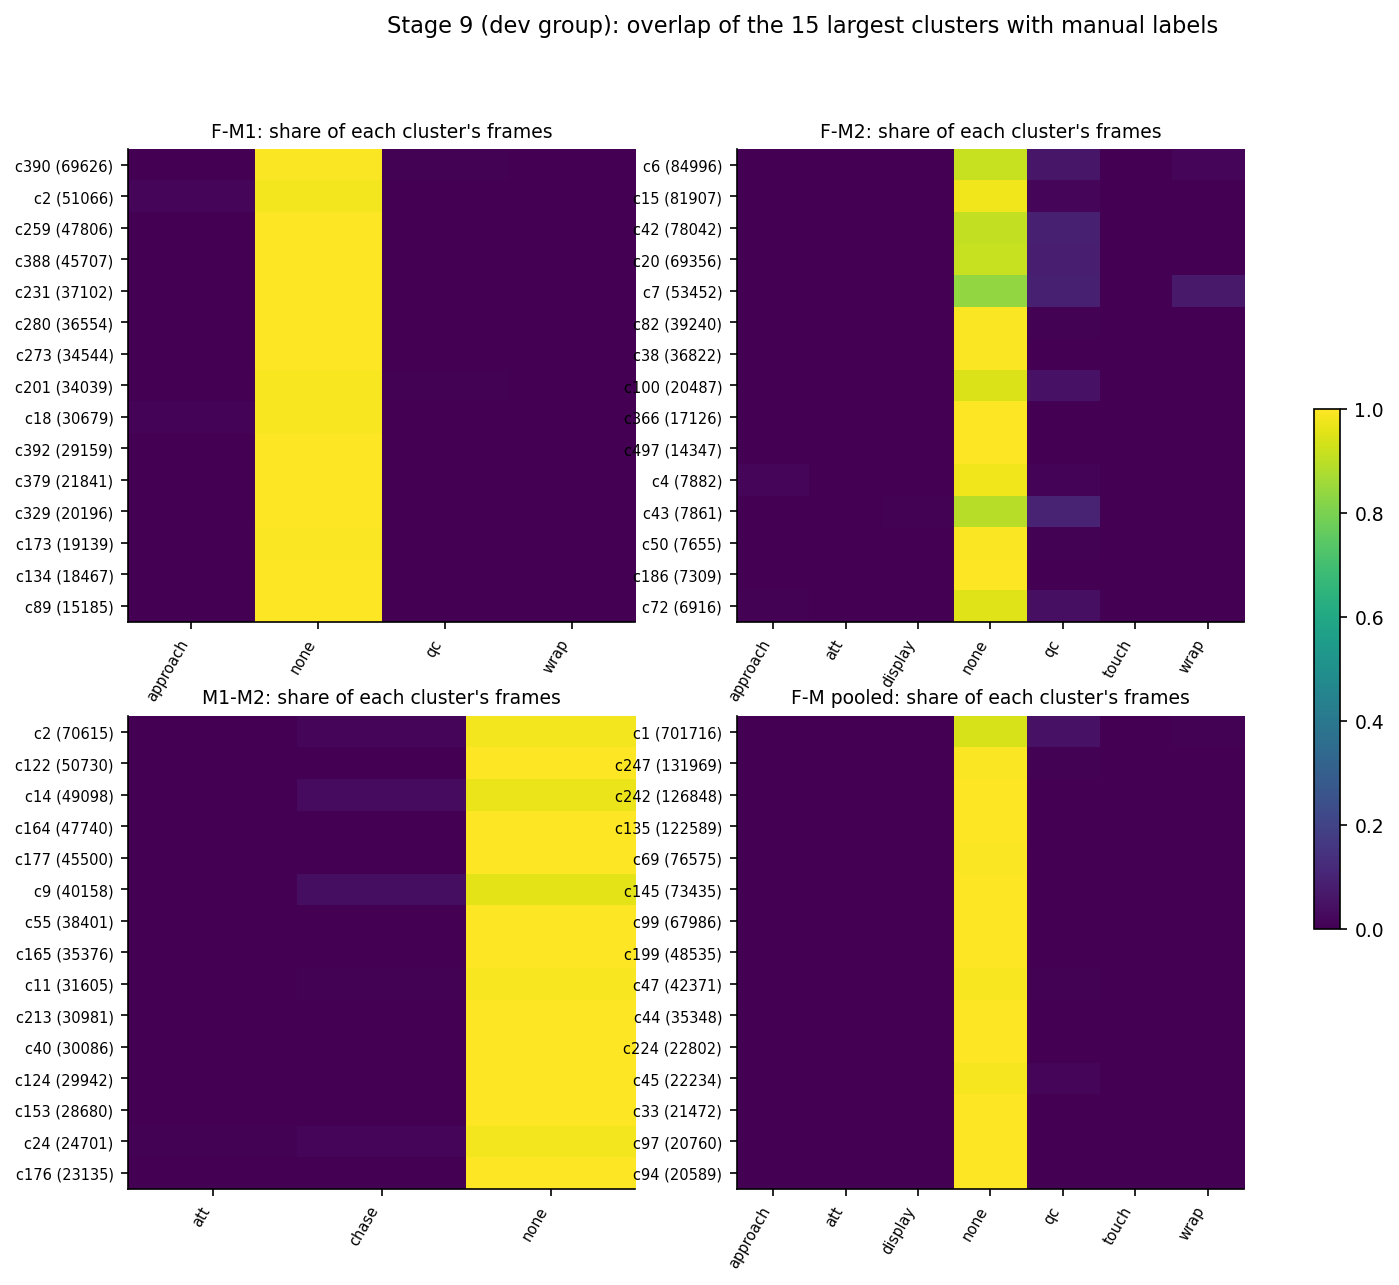

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S9_01_cluster_label_overlap_dev.png


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, s in zip(axes.ravel(), SETS):
    d = DEVFR[s]; d = d[d["cluster"] >= 0]
    top = d["cluster"].value_counts().index[:15]
    ct = pd.crosstab(d["cluster"], d["truth"]).loc[top]
    share = ct.div(ct.sum(1), axis=0)
    im = ax.imshow(share.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(top))); ax.set_yticklabels([f"c{c} ({int(ct.loc[c].sum())})" for c in top], fontsize=7)
    ax.set_title(f"{s}: share of each cluster's frames", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.5)
fig.suptitle("Stage 9 (dev group): overlap of the 15 largest clusters with manual labels")
show(fig, 9, 1, "cluster_label_overlap_dev")

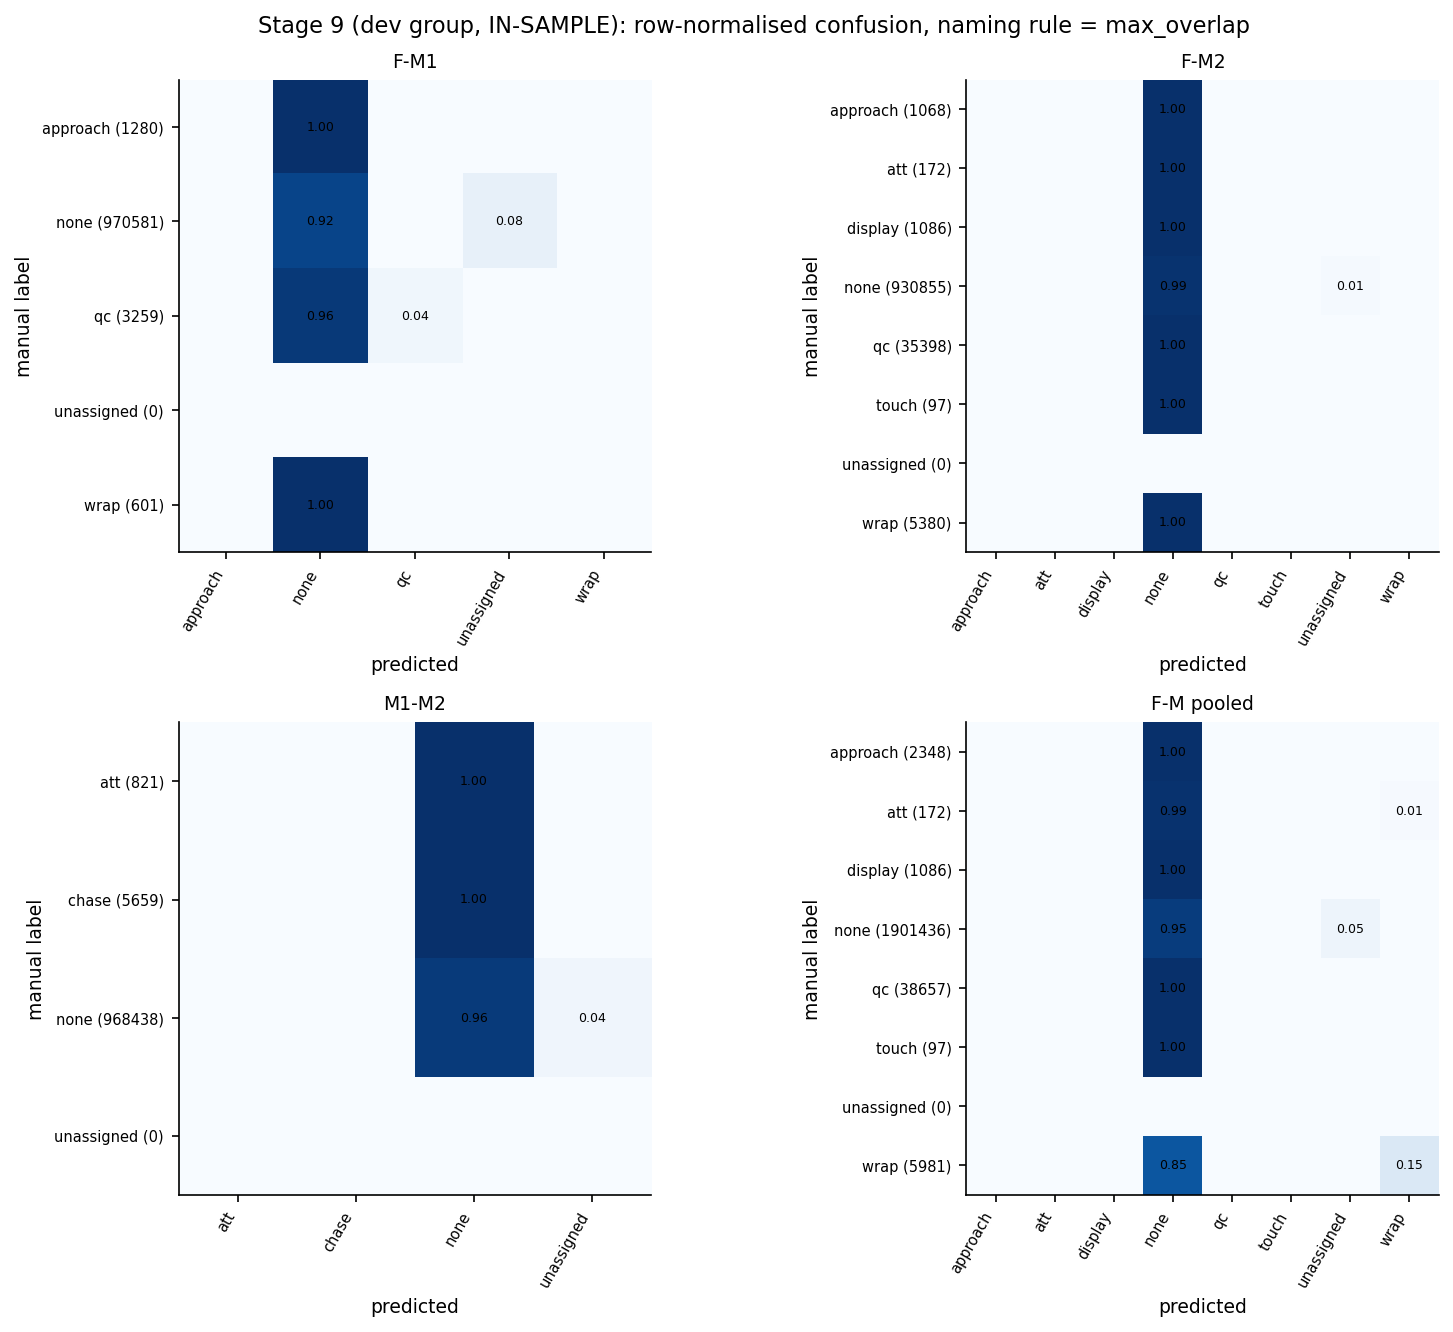

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S9_02_dev_confusion_max_overlap.png


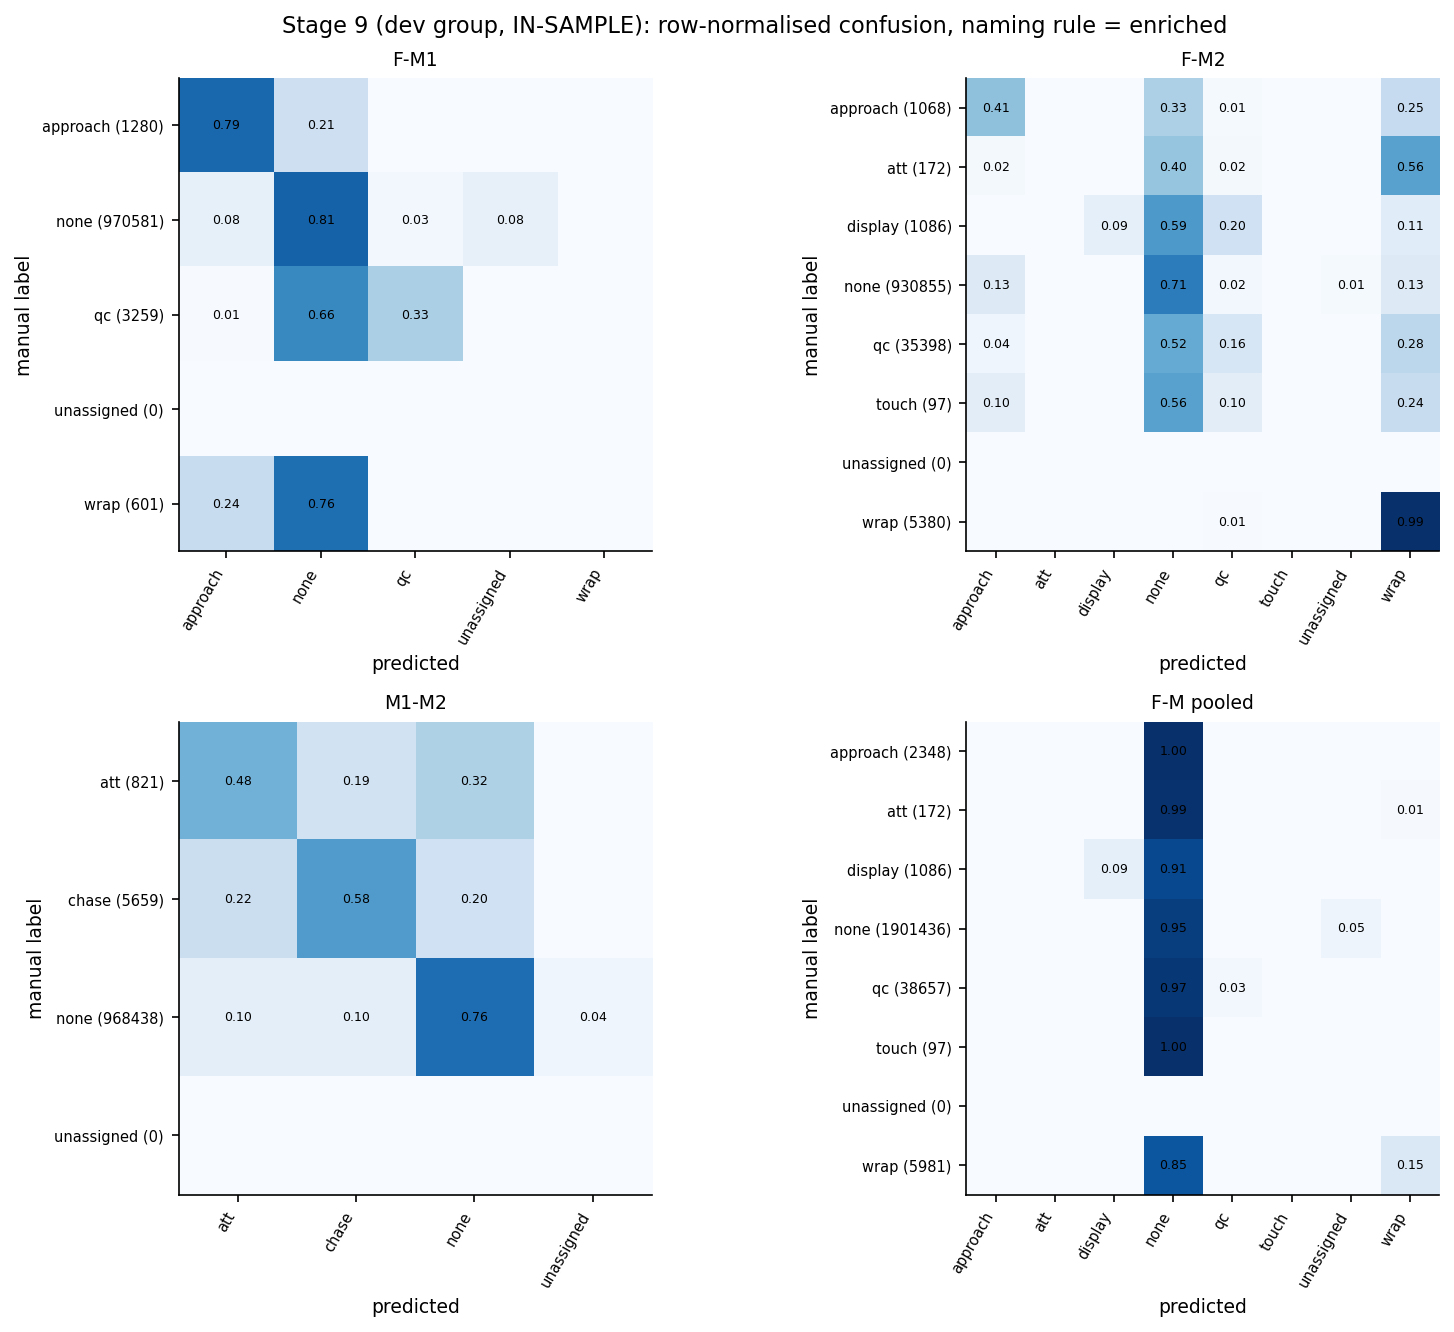

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S9_03_dev_confusion_enriched.png


In [5]:
EVAL = {}
for r in RULES:
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for ax, s in zip(axes.ravel(), SETS):
        conf, rec, scores = evaluate(DEVFR[s], MAPS[(s, r)], s)
        EVAL[(s, r)] = (conf, rec, scores)
        row = conf.div(conf.sum(1).clip(lower=1), axis=0)
        ax.imshow(row.values, vmin=0, vmax=1, cmap="Blues")
        for i in range(row.shape[0]):
            for j in range(row.shape[1]): ax.text(j, i, f"{row.values[i, j]:.2f}" if row.values[i, j] >= 0.005 else "", ha="center", va="center", fontsize=6)
        ax.set_xticks(range(row.shape[1])); ax.set_xticklabels(row.columns, rotation=60, ha="right", fontsize=7)
        ax.set_yticks(range(row.shape[0])); ax.set_yticklabels([f"{c} ({int(conf.loc[c].sum())})" for c in row.index], fontsize=7)
        ax.set_xlabel("predicted"); ax.set_ylabel("manual label"); ax.set_title(s, fontsize=9)
    fig.suptitle(f"Stage 9 (dev group, IN-SAMPLE): row-normalised confusion, naming rule = {r}")
    fig.tight_layout()
    show(fig, 9, 2 + RULES.index(r), f"dev_confusion_{r}")

       rule        set  ARI_all  NMI_all  ARI_interacting  NMI_interacting  frames  interacting_frames  unassigned_frac
max_overlap       F-M1    0.000    0.005            0.068            0.319  975721                5140            0.080
max_overlap       F-M2   -0.003    0.019            0.002            0.130  974056               43201            0.013
max_overlap      M1-M2   -0.000    0.005            0.029            0.070  974918                6480            0.040
max_overlap F-M pooled   -0.018    0.014            0.037            0.110 1949777               48341            0.046
   enriched       F-M1    0.000    0.005            0.068            0.319  975721                5140            0.080
   enriched       F-M2   -0.003    0.019            0.002            0.130  974056               43201            0.013
   enriched      M1-M2   -0.000    0.005            0.029            0.070  974918                6480            0.040
   enriched F-M pooled   -0.018    0.014

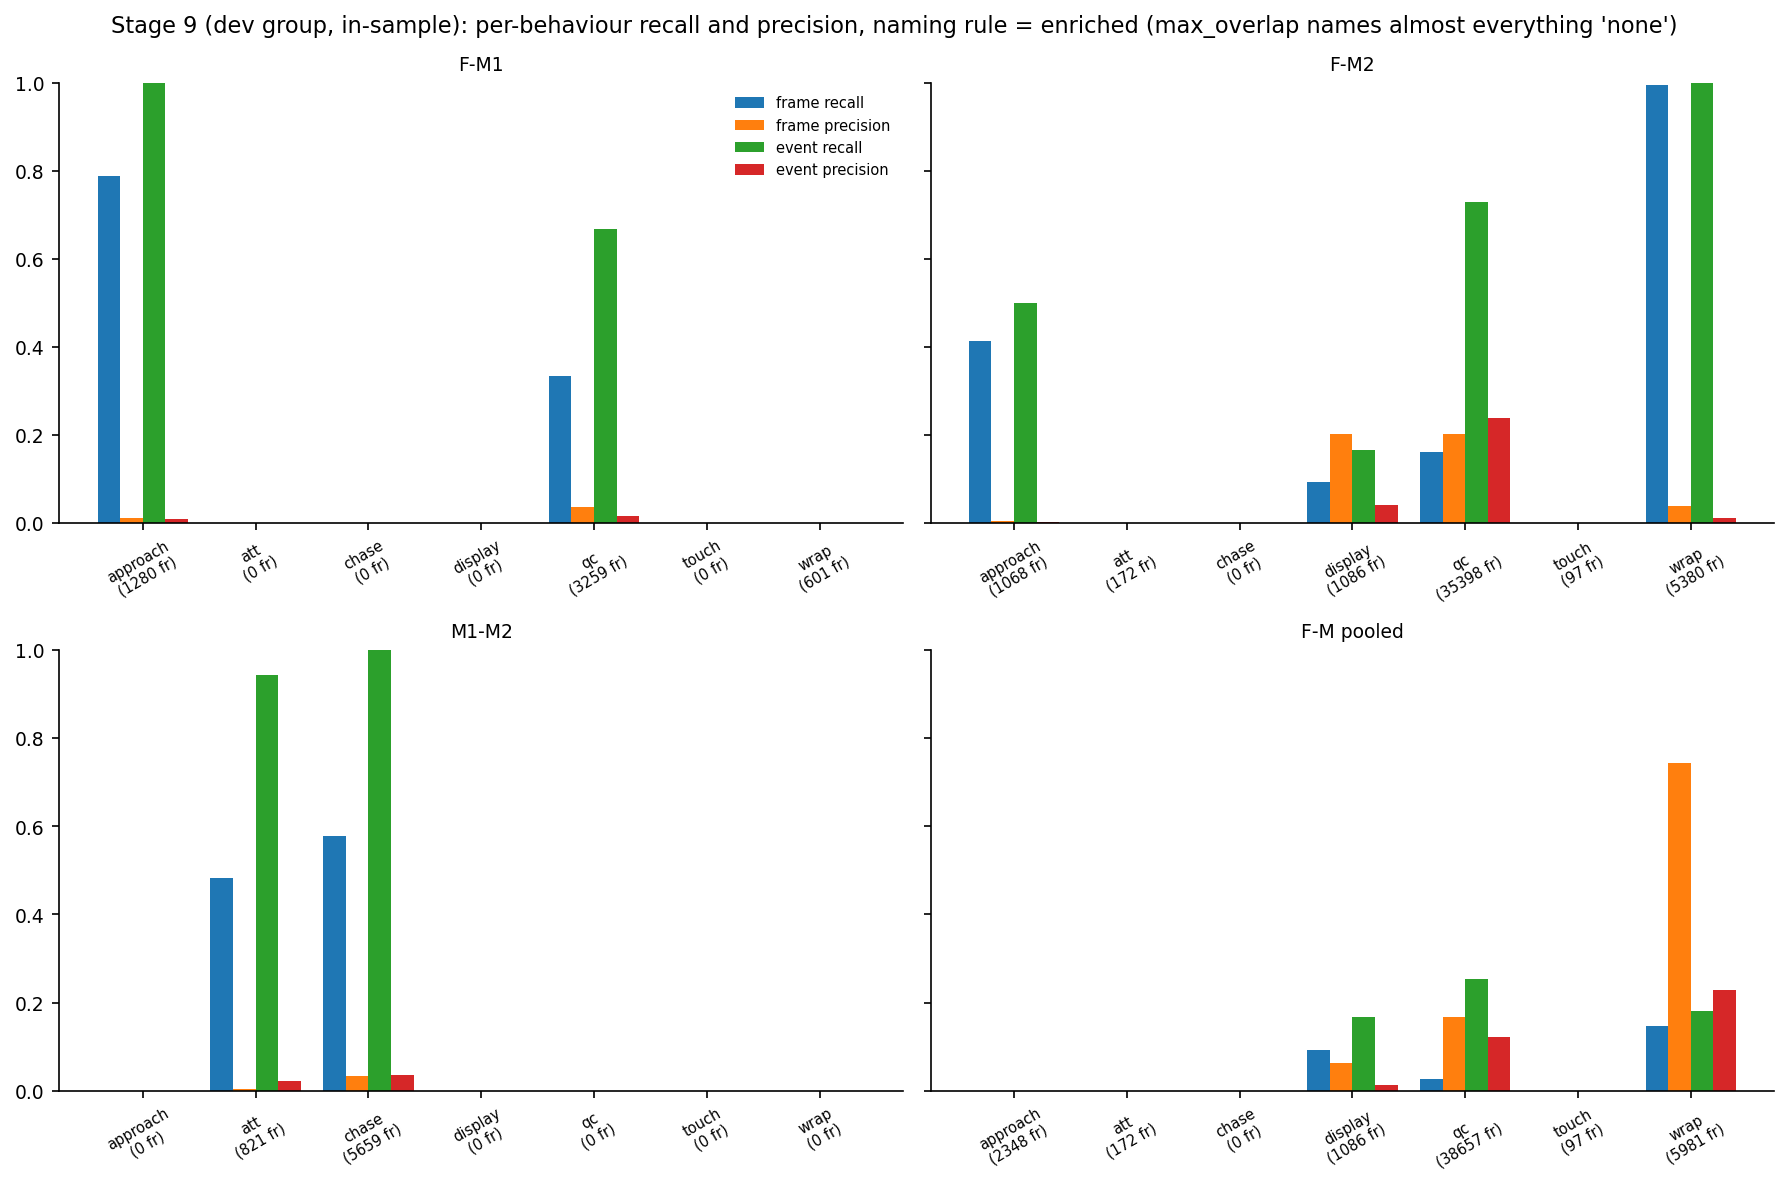

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S9_04_dev_per_behavior_recall_precision.png


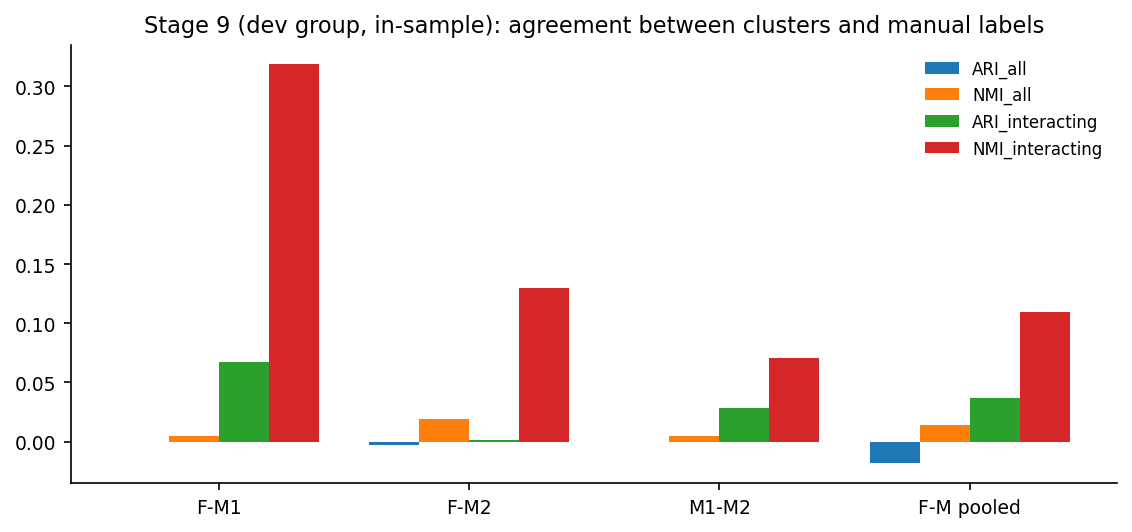

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S9_05_dev_ari_nmi.png


In [6]:
rows = []
for (s, r), (conf, rec, sc) in EVAL.items():
    for b, x in rec.iterrows():
        rows.append({"set": s, "rule": r, "class": b, **x.to_dict()})
dev_metrics = pd.DataFrame(rows); dev_metrics.to_csv(OUT / "S9_dev_metrics_per_class.csv", index=False)
dev_scores = pd.DataFrame([{"rule": r, **sc} for (s, r), (_, _, sc) in EVAL.items()]); dev_scores.to_csv(OUT / "S9_dev_ari_nmi.csv", index=False)
print(dev_scores.round(3).to_string(index=False))

beh = [b for b in sorted(set(dev_metrics["class"])) if b not in ("none", "unassigned")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, s in zip(axes.ravel(), SETS):
    d = dev_metrics[(dev_metrics["set"] == s) & (dev_metrics["rule"] == "enriched")].set_index("class").reindex(beh)
    x = np.arange(len(beh)); w = 0.2
    for k, (col, lab) in enumerate((("frame_recall", "frame recall"), ("frame_precision", "frame precision"), ("event_recall", "event recall"), ("event_precision", "event precision"))):
        ax.bar(x + (k - 1.5) * w, d[col].fillna(0), w, label=lab)
    ax.set_xticks(x); ax.set_xticklabels([f"{b}\n({int(d.loc[b, 'frames']) if np.isfinite(d.loc[b, 'frames']) else 0} fr)" for b in beh], fontsize=7, rotation=30)
    ax.set_title(s, fontsize=9); ax.set_ylim(0, 1)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Stage 9 (dev group, in-sample): per-behaviour recall and precision, naming rule = enriched (max_overlap names almost everything 'none')")
fig.tight_layout()
show(fig, 9, 4, "dev_per_behavior_recall_precision")

fig, ax = plt.subplots(figsize=(9, 3.8))
d = dev_scores[dev_scores["rule"] == "enriched"].set_index("set")
x = np.arange(len(d)); w = 0.2
for k, col in enumerate(("ARI_all", "NMI_all", "ARI_interacting", "NMI_interacting")):
    ax.bar(x + (k - 1.5) * w, d[col], w, label=col)
ax.set_xticks(x); ax.set_xticklabels(d.index); ax.legend(frameon=False, fontsize=8)
ax.set_title("Stage 9 (dev group, in-sample): agreement between clusters and manual labels")
show(fig, 9, 5, "dev_ari_nmi")

### 测试组的最终评估（门控）

`FINAL = False` 时下面不读测试组。把第一个代码格里的 `FINAL` 改成 `True` 后整本重跑才会执行。**只能做一次**：看过结果再改任何参数就不再是留出了。
严格版本：用开发组聚类和开发组命名映射，测试组帧只经“格子 → 簇”对照表（`clusters.npz` 里的标签数组）得到簇。

In [7]:
if not FINAL:
    print("FINAL is False: the test group (" + ", ".join(M.trials("test")) + ") has not been read.")
    TEST_SCORES = None
else:
    TEST = M.trials("test")
    PROC_T = {e: M.process_trial(e, PARAMS, final=True) for e in TEST}
    BOUTS_T = {e: M.bouts_of(e) for e in TEST}
    TESTFR = {s: frames_table(PROC_T, BOUTS_T, s) for s in SETS}
    rows, scs = [], []
    for r in RULES:
        fig, axes = plt.subplots(2, 2, figsize=(11, 9))
        for ax, s in zip(axes.ravel(), SETS):
            conf, rec, sc = evaluate(TESTFR[s], MAPS[(s, r)], s)
            scs.append({"rule": r, **sc})
            rows += [{"set": s, "rule": r, "class": b, **x.to_dict()} for b, x in rec.iterrows()]
            row = conf.div(conf.sum(1).clip(lower=1), axis=0)
            ax.imshow(row.values, vmin=0, vmax=1, cmap="Oranges")
            for i in range(row.shape[0]):
                for j in range(row.shape[1]): ax.text(j, i, f"{row.values[i, j]:.2f}" if row.values[i, j] >= 0.005 else "", ha="center", va="center", fontsize=6)
            ax.set_xticks(range(row.shape[1])); ax.set_xticklabels(row.columns, rotation=60, ha="right", fontsize=7)
            ax.set_yticks(range(row.shape[0])); ax.set_yticklabels([f"{c} ({int(conf.loc[c].sum())})" for c in row.index], fontsize=7)
            ax.set_xlabel("predicted"); ax.set_ylabel("manual label"); ax.set_title(s, fontsize=9)
        fig.suptitle(f"Stage 9 (TEST group, held out): row-normalised confusion, naming rule = {r}")
        fig.tight_layout()
        show(fig, 9, 6 + RULES.index(r), f"test_confusion_{r}")
    TEST_METRICS = pd.DataFrame(rows); TEST_METRICS.to_csv(OUT / "S9_test_metrics_per_class.csv", index=False)
    TEST_SCORES = pd.DataFrame(scs); TEST_SCORES.to_csv(OUT / "S9_test_ari_nmi.csv", index=False)
    print(TEST_SCORES.round(3).to_string(index=False))

FINAL is False: the test group (20260112_P_1_1_FCMC, 20260112_P_1_3_FCMC, 20260113_P_1_2_FCMC) has not been read.


## 阶段 10：合成与雌性选择

三种配对各有一套簇；**怎么把它们合成每帧一个行为，论文没有，需要设计**（适合问同事），这里不替你定。
下面只做不依赖这个设计的部分：每个 trial（组 + 天）、每个配对集合里各命名行为占有效帧的比例（`enriched` 规则），作为后续分析的基础表。

雌性选择：**独立单位是组**（天数嵌套在组内）。用混合效应模型或按组做 bootstrap；不要用“被雌鱼选中”去定义雄–雄配对的角色（循环论证）。
下面的 `group_bootstrap` 按组重采样；组数不够时拒绝给出区间。

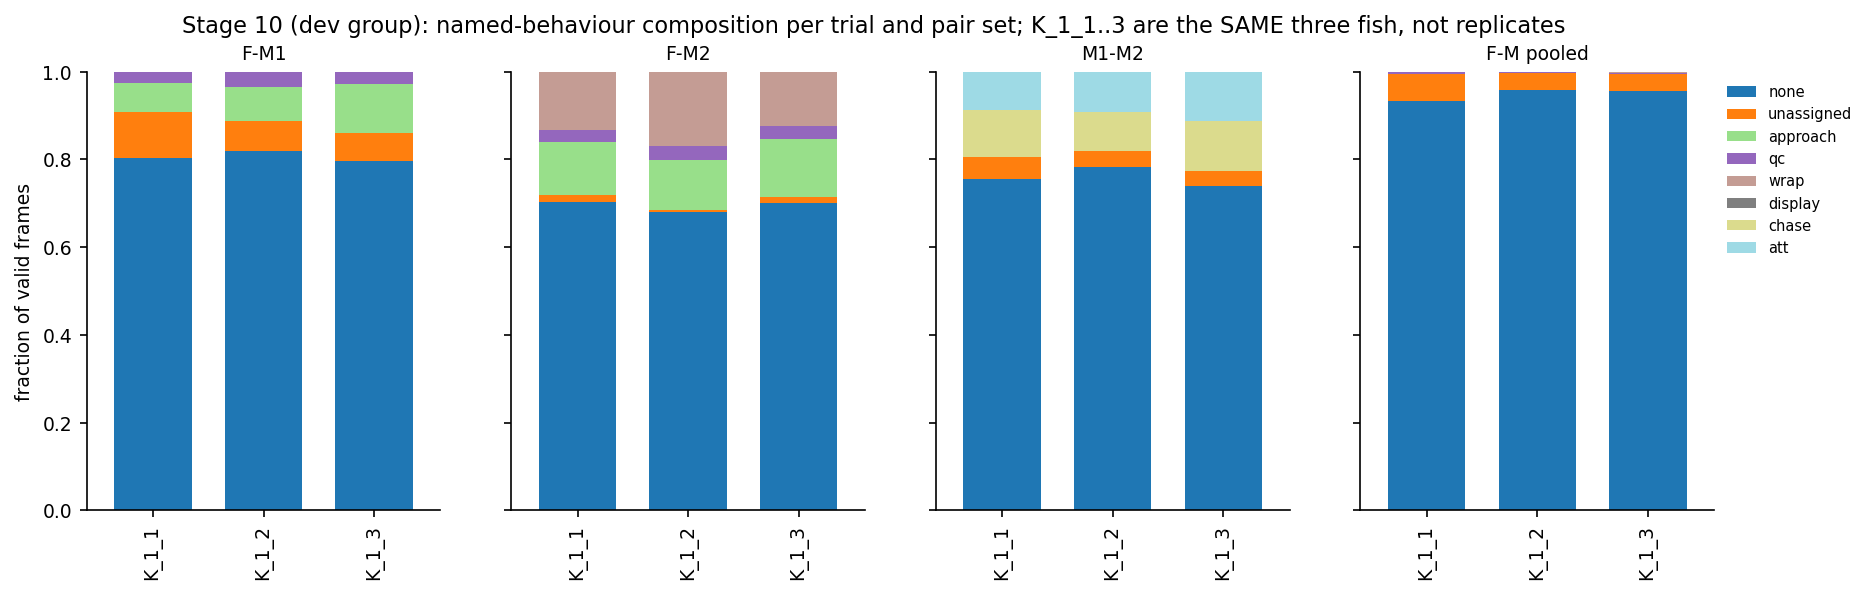

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S10_01_trial_composition_dev.png
groups with data: 1 (dev) -> group-level inference is not possible yet
group_bootstrap refused: only 1 groups: no between-group inference (need >= 8); report per-group values


In [8]:
rows = []
for s in SETS:
    d = DEVFR[s].copy()
    d["behavior"] = predict(d, MAPS[(s, "enriched")])
    for e, g in d.groupby("exp"):
        grp, day = M.parse_experiment(e)
        vc = g["behavior"].value_counts(normalize=True)
        rows.append({"set": s, "experiment": e, "group": grp, "day": day, "frames": len(g), **{f"frac_{k}": v for k, v in vc.items()}})
comp = pd.DataFrame(rows).fillna(0)
comp.to_csv(OUT / "S10_trial_composition.csv", index=False)

fig, axes = plt.subplots(1, len(SETS), figsize=(14, 3.8), sharey=True)
cols = [c for c in comp.columns if c.startswith("frac_")]
for ax, s in zip(axes, SETS):
    d = comp[comp["set"] == s].set_index("experiment")[cols]
    d.index = [i[9:-5] for i in d.index]
    d.plot.bar(stacked=True, ax=ax, legend=False, width=0.7, colormap="tab20")
    ax.set_title(s, fontsize=9); ax.set_ylim(0, 1)
axes[0].set_ylabel("fraction of valid frames")
axes[-1].legend([c[5:] for c in cols], frameon=False, fontsize=7, bbox_to_anchor=(1, 1))
fig.suptitle("Stage 10 (dev group): named-behaviour composition per trial and pair set; K_1_1..3 are the SAME three fish, not replicates")
show(fig, 10, 1, "trial_composition_dev")


def group_bootstrap(df, value, group="group", n=5000, seed=0, min_groups=8):
    """Mean of group means with a percentile interval from resampling GROUPS (days are averaged inside a group)."""
    gm = df.groupby(group)[value].mean()
    if len(gm) < min_groups:
        raise ValueError(f"only {len(gm)} groups: no between-group inference (need >= {min_groups}); report per-group values")
    rng = np.random.default_rng(seed)
    boots = [gm.sample(len(gm), replace=True, random_state=int(rng.integers(1 << 31))).mean() for _ in range(n)]
    return gm.mean(), np.percentile(boots, [2.5, 97.5])


print("groups with data:", comp["group"].nunique(), "(dev) -> group-level inference is not possible yet")
try:
    group_bootstrap(comp[comp["set"] == "F-M1"], cols[0])
except ValueError as err:
    print("group_bootstrap refused:", err)

## 阶段 11：偏差报告

你的原文写的是“见上面第 3 点最后一项”，我没有第 3 点的原文，所以这里按我的理解列出会影响结论的偏差来源，**请核对是否对应**：

1. 队列：几个组、测试组是否真的独立；K_1 三天是同三条鱼。
2. 身份：账本里的错配是不是集中在近距离帧（ms00 S0_04）。
3. 缺失：不可用帧、被去掉的骨架、超出 D_MAX、角为空，这些缺失是否随距离变化。
4. 标记：行为帧在整体中的占比（类别极不平衡）、每种行为的帧数、标记只覆盖哪些配对。

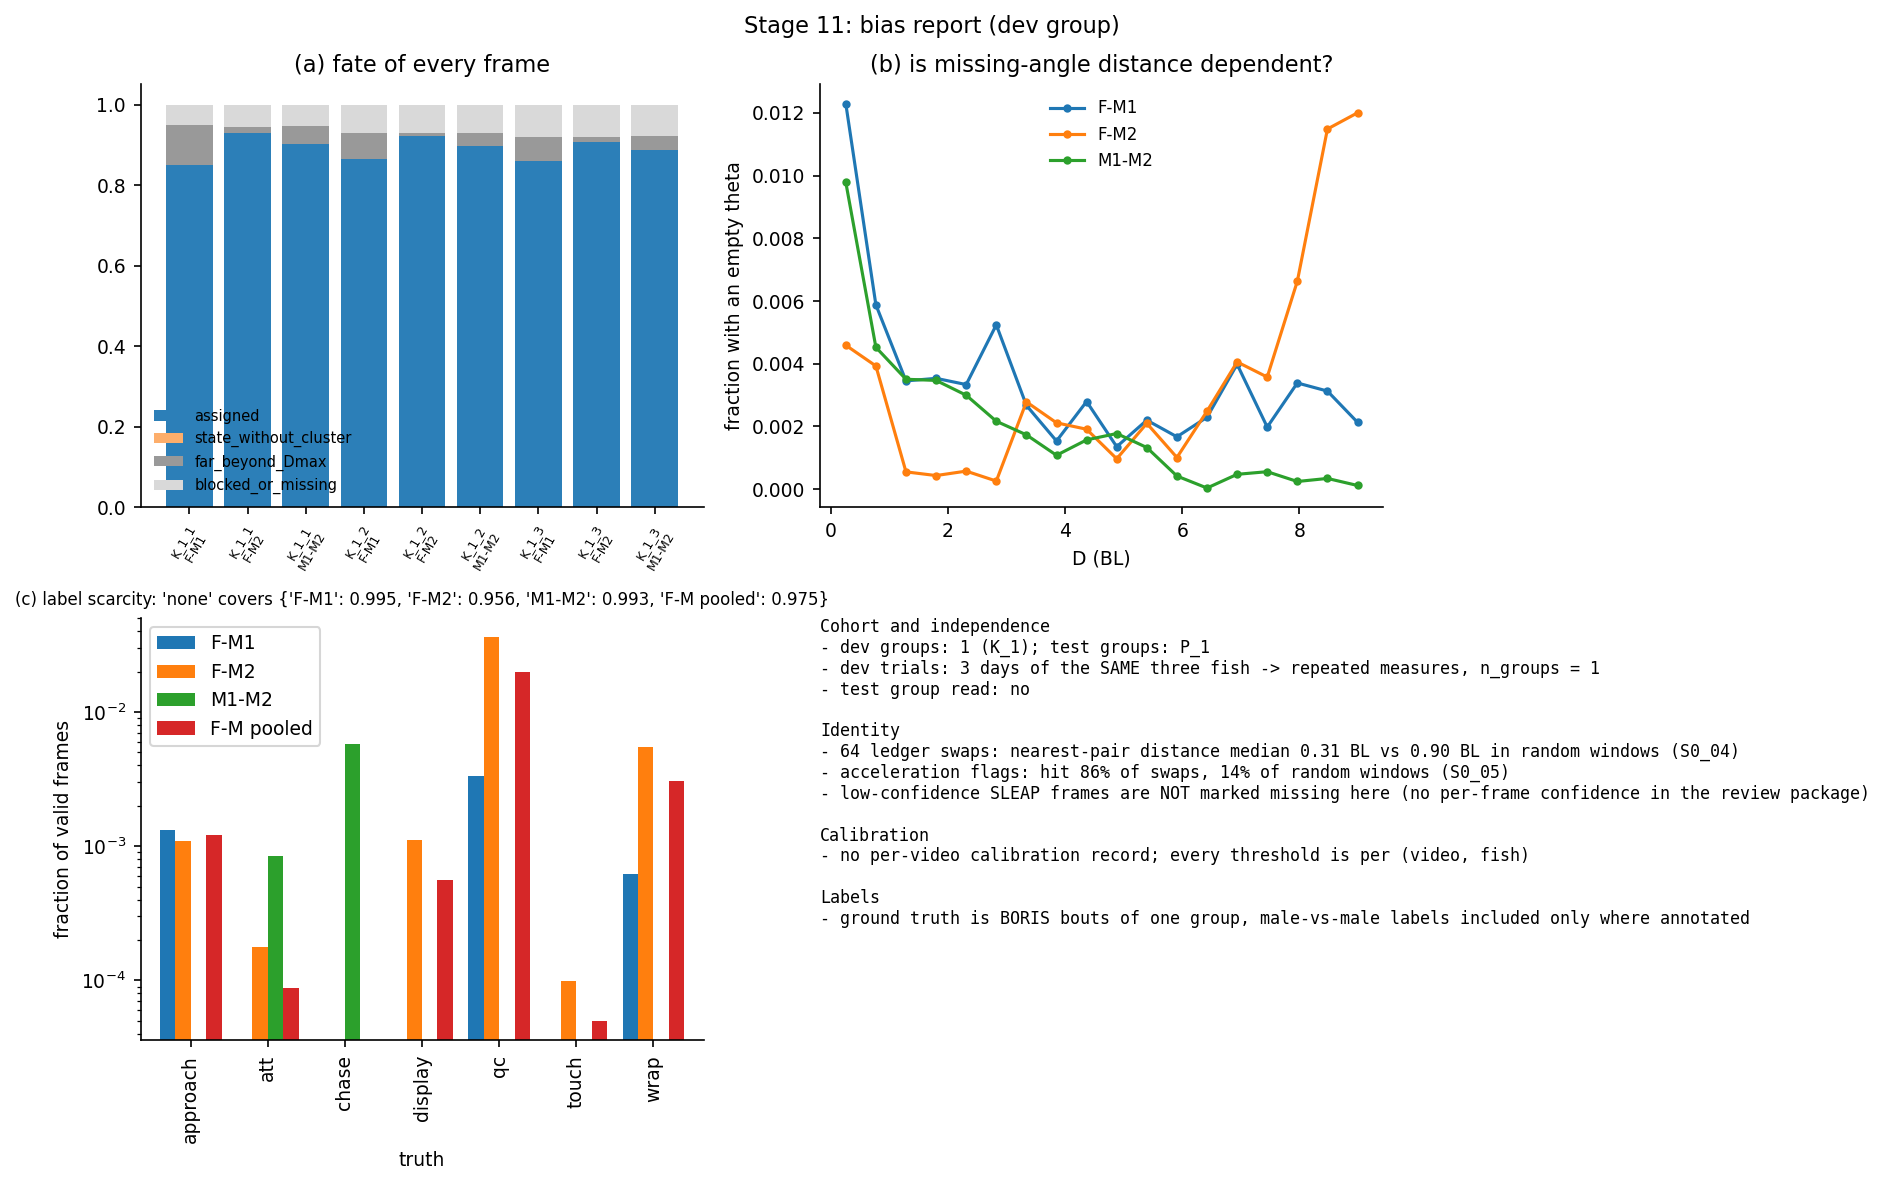

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S11_01_bias_report.png


,experiment,pair,blocked_or_missing,far_beyond_Dmax,state_without_cluster,assigned
0,20251225_K_1_1_FCMC,F-M1,0.0501,0.0994,0.0,0.8505
1,20251225_K_1_1_FCMC,F-M2,0.0548,0.0166,0.0,0.9286
2,20251225_K_1_1_FCMC,M1-M2,0.0531,0.0459,0.0,0.9010
3,20251225_K_1_2_FCMC,F-M1,0.0701,0.0651,0.0,0.8648
4,20251225_K_1_2_FCMC,F-M2,0.0711,0.0059,0.0,0.9230
5,20251225_K_1_2_FCMC,M1-M2,0.0713,0.0320,0.0,0.8968
6,20251225_K_1_3_FCMC,F-M1,0.0808,0.0600,0.0,0.8592
7,20251225_K_1_3_FCMC,F-M2,0.0799,0.0126,0.0,0.9076
8,20251225_K_1_3_FCMC,M1-M2,0.0790,0.0331,0.0,0.8880


In [9]:
S0 = PARAMS.get("stage0", {})
rows = []
for e, P in PROC.items():
    for pair in M.PAIR_NAMES:
        D, ta, tb = M.pair_units(P, pair, D_UNIT)
        st = M.bin_states(D, ta, tb, N, DMAX)
        fin = np.isfinite(D) & np.isfinite(ta) & np.isfinite(tb)
        n = len(D)
        cl = np.where(st >= 0, LAB[pair][np.maximum(st, 0)], -1)
        rows.append({"experiment": e, "pair": pair, "blocked_or_missing": float((~fin).mean()), "far_beyond_Dmax": float((fin & (D >= DMAX)).mean()),
                     "state_without_cluster": float((fin & (D < DMAX) & (cl < 0)).mean()), "assigned": float((cl >= 0).mean())})
status = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
cols_ = ["assigned", "state_without_cluster", "far_beyond_Dmax", "blocked_or_missing"]
lab_ = [f"{r.experiment[9:-5]}\n{r.pair}" for r in status.itertuples()]
bottom = np.zeros(len(status))
for c, colr in zip(cols_, ("#2c7fb8", "#fdae6b", "#999999", "#d9d9d9")):
    ax.bar(range(len(status)), status[c], bottom=bottom, color=colr, label=c); bottom += status[c].to_numpy()
ax.set_xticks(range(len(status))); ax.set_xticklabels(lab_, fontsize=6, rotation=60); ax.legend(frameon=False, fontsize=7)
ax.set_title("(a) fate of every frame")

ax = axes[0, 1]
edges = np.linspace(0, DMAX, 19)
for pair in M.PAIR_NAMES:
    Ds, miss = [], []
    for P in PROC.values():
        D, ta, tb = M.pair_units(P, pair, D_UNIT)
        okD = np.isfinite(D)
        Ds.append(D[okD]); miss.append((~np.isfinite(ta) | ~np.isfinite(tb))[okD])
    Ds, miss = np.concatenate(Ds), np.concatenate(miss)
    idx = np.digitize(Ds, edges) - 1
    ax.plot((edges[:-1] + edges[1:]) / 2, [miss[idx == i].mean() if (idx == i).any() else np.nan for i in range(len(edges) - 1)], "-o", ms=3, label=pair)
ax.set_xlabel("D (BL)"); ax.set_ylabel("fraction with an empty theta"); ax.legend(frameon=False, fontsize=8); ax.set_title("(b) is missing-angle distance dependent?")

ax = axes[1, 0]
lab_frac = pd.DataFrame({s: DEVFR[s]["truth"].value_counts(normalize=True) for s in SETS}).fillna(0)
lab_frac.drop(index="none", errors="ignore").plot.bar(ax=ax, width=0.8)
ax.set_ylabel("fraction of valid frames"); ax.set_yscale("log"); ax.set_title(f"(c) label scarcity: 'none' covers {lab_frac.loc['none'].round(3).to_dict()}", fontsize=8)

ax = axes[1, 1]; ax.axis("off")
sw = S0
txt = ["Cohort and independence",
       f"- dev groups: {S0.get('n_groups_dev', '?')} ({', '.join(S0.get('dev_groups', []))}); test groups: {', '.join(S0.get('test_groups', []))}",
       f"- dev trials: {len(DEV)} days of the SAME three fish -> repeated measures, n_groups = {len(S0.get('dev_groups', []))}",
       "- test group read: " + ("YES (FINAL=True)" if FINAL else "no"),
       "", "Identity",
       f"- {S0.get('n_swaps', '?')} ledger swaps: nearest-pair distance median {S0.get('swap_median_nearest_pair_BL', float('nan')):.2f} BL"
       f" vs {S0.get('random_window_median_nearest_pair_BL', float('nan')):.2f} BL in random windows (S0_04)",
       f"- acceleration flags: hit {S0.get('accel_swap_hit_rate', float('nan')):.0%} of swaps, {S0.get('accel_chance_rate', float('nan')):.0%} of random windows (S0_05)",
       "- low-confidence SLEAP frames are NOT marked missing here (no per-frame confidence in the review package)",
       "", "Calibration", "- no per-video calibration record; every threshold is per (video, fish)",
       "", "Labels", "- ground truth is BORIS bouts of one group, male-vs-male labels included only where annotated"]
ax.text(0, 1, "\n".join(txt), va="top", fontsize=8, family="monospace")
fig.suptitle("Stage 11: bias report (dev group)")
fig.tight_layout()
show(fig, 11, 1, "bias_report")
status.to_csv(OUT / "S11_bias_report.csv", index=False)
status.round(4)